# Прогноз отсутствия педагога в следующем году

Цель `target=1` означает отсутствие в следующем годовом срезе системы, а не установленную
причину увольнения. Переход школы имеет `target=0`. В 2024 исходы неизвестны.

**Порядок работы:** проверка данных → сравнение моделей и сетка параметров только внутри 2022
→ выбор порога по прогнозам 2022 вне обучения → проверка 2022 → 2023
→ обучение выбранного рецепта на 2022+2023 и экспорт для 2024.

В предыдущих опытах 2023 уже изучался, поэтому называем его ретроспективной временной
проверкой. В этом запуске его метки не используются для настройки или выбора модели.
Все объяснения и результаты находятся здесь. Запуск: **Restart and Run All** из корня проекта
или `notebooks/`, Python из `.venv`. Последняя ячейка обновляет файлы в `models/`.

## 1. Данные и проверки

Читаем готовую кадровую витрину. Не пересобираем её и не меняем исходные данные.
Проверяем уникальность педагога в году и неизвестные исходы 2024, чтобы не обучиться на ложных метках.

In [1]:
from pathlib import Path
from itertools import product
from copy import deepcopy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    brier_score_loss, log_loss, confusion_matrix,
    PrecisionRecallDisplay, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

root = Path.cwd()
if not (root / "dashboard/app.py").is_file():
    root = root.parent

df = pd.read_parquet(root / "data/teachers.parquet")
assert not df.duplicated(["id", "year"]).any()
assert set(df["year"]) == {2022, 2023, 2024}
assert df.loc[df["year"] < 2024, "target"].isin([0, 1]).all()
assert df.loc[df["year"] == 2024, "target"].isna().all()
assert (df.loc[df["year"] < 2024, "target"] ==
        df.loc[df["year"] < 2024, "mobility_status"].eq(2)).all()

display(df.groupby("year")["target"].agg(["size", "count", "mean"]))

,size,count,mean
year,,,
2022,17396,17396,0.149230
2023,17394,17394,0.132172
2024,17933,0,NaN


## 2. Сопоставимые признаки

Оставляем возраст, стаж, нагрузку, образование, наличие ПК/ПП, квалификацию и округ.
Идентификатор, год, школа и исходы в признаки не входят.

Исключаем три поля по известным особенностям источника:
- `pk_hours_3y`: в 2022 доступен один год часов, в 2023 два, в 2024 три;
- `speciality`: в 2022 почти всё поле пусто, а в следующих годах заполнено;
- `edu_speciality_match`: зависит от заполненности `speciality`.

Это выбор по смыслу и доступности данных, а не по улучшению метрики 2023.
Числовые и бинарные поля уже готовы в parquet; категории CatBoost использует напрямую.

Противоречивые значения стажа оставлены NaN с флагом `experience_valid` в витрине.
CatBoost обрабатывает числовые NaN напрямую. Для моделей сравнения медианы обучаем
только на обучающей части каждого разбиения; флаг качества в признаки не добавляем.

In [2]:
numeric = [
    "age", "experience_age_pedagogic_clean", "experience_age_other_clean",
    "n_subjects", "n_parallels", "min_parallel", "max_parallel",
    "sex", "class_manager", "edu_higher", "edu_pedagogical",
    "pk_recent", "pk_this_year", "retraining",
]
categorical = ["main_position_cat", "academic_degree_cat", "category_qual_cat", "district"]
features = numeric + categorical
excluded_features = ["pk_hours_3y", "speciality", "edu_speciality_match"]
assert df[categorical].notna().all().all()

display(df.groupby("year").agg(
    unknown_speciality=("speciality", lambda s: s.eq("не указано").mean()),
    missing_edu_match=("edu_speciality_match", lambda s: s.isna().mean()),
    mean_hours=("pk_hours_3y", "mean"),
))
print("Признаков:", len(features))

train = df.loc[df["year"] == 2022].reset_index(drop=True)
test = df.loc[df["year"] == 2023].reset_index(drop=True)
forecast = df.loc[df["year"] == 2024].reset_index(drop=True)
X_train, y_train = train[features], train["target"].astype(int)
X_test, y_test = test[features], test["target"].astype(int)
X_forecast = forecast[features]

,unknown_speciality,missing_edu_match,mean_hours
year,,,
2022,0.970625,0.971718,32.685272
2023,0.100437,0.121881,60.717776
2024,0.097474,0.114816,75.169018


Признаков: 18


## 3. Одинаковая проверка всех моделей

Делим **только 2022** на три части с одинаковой долей уходов. Каждый прогноз OOF
получен моделью, которая не обучалась на этой строке. Все модели получают одинаковые разбиения.
Это внутренняя проверка одного года; перенос на следующий год проверяем отдельно.

Основная метрика — **AP (average precision)**: она оценивает поиск редкого класса ухода.
Дополнительно считаем ROC-AUC, Brier и logloss. У Brier/logloss меньше — лучше.
Постоянная доля ухода — ориентир качества вероятностей; обычная accuracy не выбирает победителя.

Оставляем одну небольшую функцию для метрик и одну для трёх обучений.

In [3]:
cv = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=42).split(X_train, y_train))

def probability_metrics(y, p):
    return {
        "AP": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "Brier": brier_score_loss(y, p),
        "Logloss": log_loss(y, p),
        "mean_probability": float(np.mean(p)),
    }

def oof_predict(estimator):
    p = np.zeros(len(y_train))
    for fit_idx, valid_idx in cv:
        fitted = deepcopy(estimator)
        fitted.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        p[valid_idx] = fitted.predict_proba(X_train.iloc[valid_idx])[:, 1]
    return p

## 4. Простые модели для сравнения с HW8

Берём постоянный прогноз, логистическую регрессию, дерево с весами и случайный лес.
Это семейства из HW8, но теперь они используют те же 18 признаков, что и CatBoost.
Поэтому их результаты нельзя выдавать за прежние сохранённые оценки HW8.

Заполнение числовых пропусков, one-hot и масштабирование для логистической регрессии находятся внутри Pipeline:
они обучаются заново на каждой обучающей части. Для деревьев масштабирование не требуется.
SMOTE не добавляем: в HW8 он не дал преимущества, а код и трактовка вероятностей усложняются.

In [4]:
linear_preparation = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
])
tree_preparation = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
])
models = {
    "Постоянная доля": DummyClassifier(strategy="prior"),
    "Логистическая регрессия": make_pipeline(
        linear_preparation, LogisticRegression(max_iter=2000, random_state=42)),
    "Дерево с весами": make_pipeline(
        tree_preparation, DecisionTreeClassifier(
            max_depth=7, min_samples_leaf=20, class_weight="balanced", random_state=42)),
    "Случайный лес": make_pipeline(
        tree_preparation, RandomForestClassifier(
            n_estimators=150, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=4)),
}
cv_predictions = {}
rows = []
for name, estimator in models.items():
    p = oof_predict(estimator)
    cv_predictions[name] = p
    rows.append({"model": name, **probability_metrics(y_train, p)})
    print(name, "AP =", round(rows[-1]["AP"], 4), flush=True)

display(pd.DataFrame(rows).round(4))

Постоянная доля AP = 0.1492


Логистическая регрессия AP = 0.2995


Дерево с весами AP = 0.2831


Случайный лес AP = 0.3203


,model,AP,ROC_AUC,Brier,Logloss,mean_probability
0,Постоянная доля,0.1492,0.4998,0.1270,0.4214,0.1492
1,Логистическая регрессия,0.2995,0.6924,0.1180,0.3901,0.1491
2,Дерево с весами,0.2831,0.6783,0.2153,0.6755,0.4336
3,Случайный лес,0.3203,0.7164,0.1158,0.3820,0.1488


## 5. Небольшая сетка CatBoost вместо Optuna

Для учебного проекта проверяем восемь явных комбинаций: две глубины, два числа деревьев
и наличие весов классов. Скорость обучения 0,06 и регуляризацию 5 фиксируем.
Это ограниченный поиск, а не утверждение о глобально лучших параметрах.

Преимущество такого кода — видно каждую попытку и легко повторить результат.
Число деревьев входит в сетку, поэтому early stopping и отдельный eval_set не нужны.
**Все настройки после выбора сохраняются**, число деревьев не умножается на размер выборки.

In [5]:
common_params = {
    "learning_rate": 0.06,
    "l2_leaf_reg": 5,
    "border_count": 64,
    "bootstrap_type": "Bernoulli",
    "subsample": 0.8,
    "rsm": 0.8,
    "random_seed": 42,
    "thread_count": 4,
    "verbose": False,
    "allow_writing_files": False,
    "cat_features": categorical,
}
for depth, iterations, weights in product([4, 6], [150, 300], ["None", "Balanced"]):
    name = f"CatBoost depth={depth}, trees={iterations}, weights={weights}"
    estimator = CatBoostClassifier(
        **common_params, depth=depth, iterations=iterations, auto_class_weights=weights)
    models[name] = estimator
    p = oof_predict(estimator)
    cv_predictions[name] = p
    rows.append({"model": name, **probability_metrics(y_train, p)})
    print(name, "AP =", round(rows[-1]["AP"], 4), flush=True)

cv_results = pd.DataFrame(rows).set_index("model")
baseline_brier = cv_results.loc["Постоянная доля", "Brier"]
cv_results["probability_check"] = cv_results["Brier"] < baseline_brier
display(cv_results.sort_values("AP", ascending=False).round(4))

CatBoost depth=4, trees=150, weights=None AP = 0.3204


CatBoost depth=4, trees=150, weights=Balanced AP = 0.3146


CatBoost depth=4, trees=300, weights=None AP = 0.3266


CatBoost depth=4, trees=300, weights=Balanced AP = 0.3207


CatBoost depth=6, trees=150, weights=None AP = 0.3233


CatBoost depth=6, trees=150, weights=Balanced AP = 0.3159


CatBoost depth=6, trees=300, weights=None AP = 0.3266


CatBoost depth=6, trees=300, weights=Balanced AP = 0.3188


,AP,ROC_AUC,Brier,Logloss,mean_probability,probability_check
model,,,,,,
"CatBoost depth=4, trees=300, weights=None",0.3266,0.7173,0.1155,0.3811,0.1501,True
"CatBoost depth=6, trees=300, weights=None",0.3266,0.7159,0.1156,0.3817,0.1497,True
"CatBoost depth=6, trees=150, weights=None",0.3233,0.7171,0.1157,0.3816,0.1496,True
"CatBoost depth=4, trees=300, weights=Balanced",0.3207,0.7137,0.2073,0.6040,0.4400,False
"CatBoost depth=4, trees=150, weights=None",0.3204,0.7153,0.1159,0.3826,0.1494,True
Случайный лес,0.3203,0.7164,0.1158,0.3820,0.1488,True
"CatBoost depth=6, trees=300, weights=Balanced",0.3188,0.7120,0.1985,0.5838,0.4225,False
"CatBoost depth=6, trees=150, weights=Balanced",0.3159,0.7160,0.2100,0.6096,0.4470,False
"CatBoost depth=4, trees=150, weights=Balanced",0.3146,0.7143,0.2120,0.6145,0.4510,False


## 6. Выбор модели и проверка устойчивости

Нам нужны и полезное ранжирование, и осмысленные вероятности для Dash.
Поэтому среди моделей с Brier лучше постоянной доли выбираем наибольший AP.
Правило задано до проверки 2023. Сложную калибровку не добавляем, если модель без весов
уже проходит проверку вероятностей; её перенос между годами всё равно нужно оценить.

Для выбранного рецепта дополнительно меняем случайное разбиение 2022 три раза.
По этим результатам параметры не перенастраиваем: показываем чувствительность к разбиению.

In [6]:
eligible = cv_results[cv_results["probability_check"]]
assert not eligible.empty, "Ни одна модель не улучшила Brier постоянного прогноза"
best_name = eligible["AP"].idxmax()
best_estimator = models[best_name]
assert isinstance(best_estimator, CatBoostClassifier), "Победитель не CatBoost: нужен другой экспорт"
oof_probability = cv_predictions[best_name]
best_params = best_estimator.get_params().copy()
print("Выбрано по 2022:", best_name)

stability_rows = []
for seed in [42, 17, 123]:
    fit_idx, valid_idx = train_test_split(
        np.arange(len(train)), test_size=0.2, stratify=y_train, random_state=seed)
    fitted = deepcopy(best_estimator)
    fitted.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    p = fitted.predict_proba(X_train.iloc[valid_idx])[:, 1]
    stability_rows.append({"split_seed": seed, **probability_metrics(y_train.iloc[valid_idx], p)})
stability = pd.DataFrame(stability_rows)
display(stability.round(4))

Выбрано по 2022: CatBoost depth=4, trees=300, weights=None


,split_seed,AP,ROC_AUC,Brier,Logloss,mean_probability
0,42,0.3117,0.7141,0.1165,0.3834,0.1544
1,17,0.3424,0.7293,0.1142,0.3767,0.1492
2,123,0.3469,0.7257,0.1142,0.3771,0.1488


## 7. Порог выбираем только по 2022

Для отдельного списка внимания ориентируемся на recall не ниже 70% на OOF-прогнозах 2022.
Среди подходящих порогов выбираем наибольшую precision. На следующем году recall может отличаться.
Это экспериментальный порог, а не граница «высокого риска» в Dash.
В приложении сохраняются границы 0,25/0,50.

In [7]:
target_recall = 0.70
precision, recall, thresholds = precision_recall_curve(y_train, oof_probability)
allowed = np.flatnonzero(recall[:-1] >= target_recall)
best_index = allowed[np.argmax(precision[:-1][allowed])]
evaluation_threshold = float(thresholds[best_index])
print("Порог по OOF 2022:", round(evaluation_threshold, 4))
print("OOF recall:", round(float(recall[best_index]), 4))
print("OOF precision:", round(float(precision[best_index]), 4))

Порог по OOF 2022: 0.132
OOF recall: 0.7015
OOF precision: 0.2433


## 8. Временная проверка: 2022 → 2023

Обучаем выбранную модель на всём 2022 с уже заданными параметрами.
**2023 не передаём в fit, не используем для выбора порога или числа деревьев.**
Метрики ниже относятся к этой оценочной модели, а не к будущей модели, обученной на двух годах.
Сравнение с постоянным прогнозом помогает оценить реальную пользу.

In [8]:
evaluation_model = deepcopy(best_estimator)
evaluation_model.fit(X_train, y_train)
test_probability = evaluation_model.predict_proba(X_test)[:, 1]
baseline_probability = np.full(len(test), y_train.mean())
test_metrics = probability_metrics(y_test, test_probability)
display(pd.DataFrame([
    {"model": "Выбранная модель 2022 → 2023", **test_metrics},
    {"model": "Постоянная доля 2022", **probability_metrics(y_test, baseline_probability)},
]).set_index("model").round(4))

threshold_rows = []
for label, threshold in [("Порог по OOF 2022", evaluation_threshold),
                         ("Граница Dash 0.25", 0.25), ("Граница Dash 0.50", 0.50)]:
    pred = test_probability >= threshold
    threshold_rows.append({
        "rule": label, "threshold": threshold,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "flagged": int(pred.sum()),
    })
threshold_results = pd.DataFrame(threshold_rows).set_index("rule")
display(threshold_results.round(4))
display(pd.DataFrame(
    confusion_matrix(y_test, test_probability >= evaluation_threshold),
    index=["Факт: присутствует", "Факт: отсутствует"],
    columns=["Прогноз: присутствует", "Прогноз: отсутствует"],
))

top_rows = []
order = np.argsort(-test_probability, kind="stable")
for share in [0.10, 0.20]:
    chosen = order[:int(np.ceil(len(test) * share))]
    top_rows.append({
        "share": share, "people": len(chosen),
        "precision": y_test.iloc[chosen].mean(),
        "recall": y_test.iloc[chosen].sum() / y_test.sum(),
        "lift": y_test.iloc[chosen].mean() / y_test.mean(),
    })
top_results = pd.DataFrame(top_rows)
display(top_results.round(4))

,AP,ROC_AUC,Brier,Logloss,mean_probability
model,,,,,
Выбранная модель 2022 → 2023,0.2967,0.7233,0.1054,0.3542,0.1503
Постоянная доля 2022,0.1322,0.5000,0.1150,0.3917,0.1492


,threshold,precision,recall,F1,balanced_accuracy,flagged
rule,,,,,,
Порог по OOF 2022,0.132,0.2179,0.7199,0.3345,0.6632,7596
Граница Dash 0.25,0.250,0.3353,0.3497,0.3423,0.6221,2398
Граница Dash 0.50,0.500,0.4815,0.0452,0.0827,0.5189,216


,Прогноз: присутствует,Прогноз: отсутствует
Факт: присутствует,9154,5941
Факт: отсутствует,644,1655


,share,people,precision,recall,lift
0,0.1,1740,0.3586,0.2714,2.7133
1,0.2,3479,0.2920,0.4419,2.2095


## 9. Проверка ранжирования и вероятностей

PR-кривая показывает компромисс между precision и recall.
На графике калибровки сравниваем среднюю вероятность с фактической частотой в группах.
Калибровку здесь **только оцениваем**, а не обучаем на 2023.
Хороший ROC-AUC сам по себе не означает точные вероятности или причинный эффект.

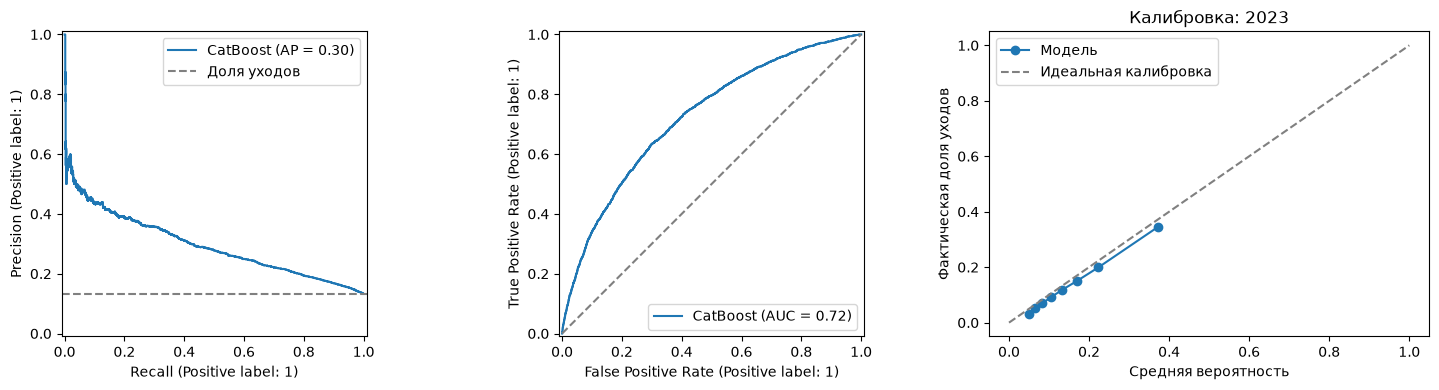

,mean_probability,observed_rate
0,0.0497,0.0317
1,0.0662,0.0511
2,0.0835,0.0699
3,0.1047,0.0915
4,0.1318,0.1173
5,0.1704,0.1509
6,0.2232,0.1992
7,0.3728,0.3457


Фактическая доля 2023: 0.1322
Средний прогноз 2023: 0.1503


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[0], name="CatBoost")
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label="Доля уходов")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="CatBoost")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
observed, predicted = calibration_curve(y_test, test_probability, n_bins=8, strategy="quantile")
axes[2].plot(predicted, observed, "o-", label="Модель")
axes[2].plot([0, 1], [0, 1], "--", color="gray", label="Идеальная калибровка")
axes[2].set(xlabel="Средняя вероятность", ylabel="Фактическая доля уходов", title="Калибровка: 2023")
axes[2].legend()
plt.tight_layout()
plt.show()

calibration_table = pd.DataFrame({"mean_probability": predicted, "observed_rate": observed})
display(calibration_table.round(4))
print("Фактическая доля 2023:", round(y_test.mean(), 4))
print("Средний прогноз 2023:", round(float(test_probability.mean()), 4))

## 10. Важность признаков

Показываем встроенную важность CatBoost (PredictionValuesChange).
Она объясняет вклад признаков в прогноз, но не доказывает причины ухода.
Это не SHAP и не оценка эффекта кадровой меры.

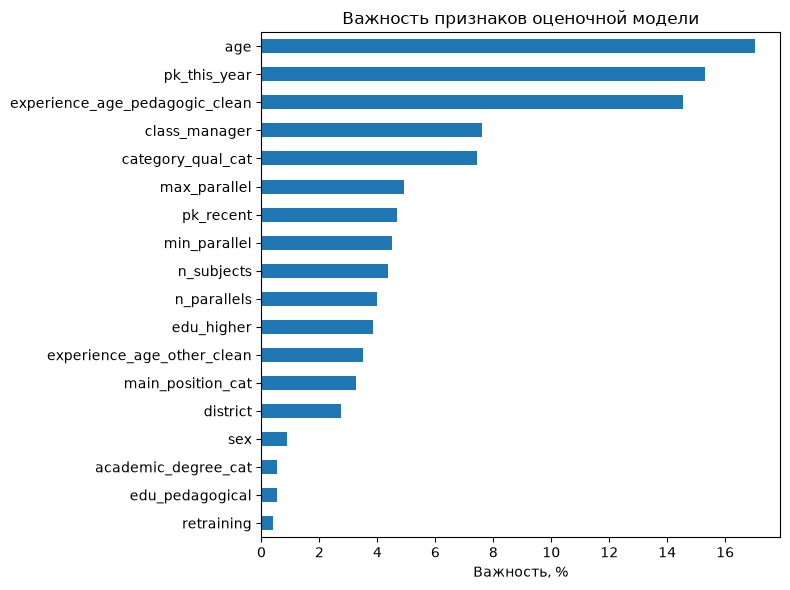

,importance
age,17.039876
pk_this_year,15.292512
experience_age_pedagogic_clean,14.532364
class_manager,7.613711
category_qual_cat,7.422790
max_parallel,4.922873
pk_recent,4.663732
min_parallel,4.506219
n_subjects,4.351147
n_parallels,3.979467


In [10]:
importance = pd.Series(evaluation_model.feature_importances_, index=features).sort_values()
importance.plot.barh(figsize=(8, 6), title="Важность признаков оценочной модели")
plt.xlabel("Важность, %")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).head(10).to_frame("importance"))

## 11. Прогноз 2024: используем оба года с известными исходами

Оценка завершена, рецепт зафиксирован. Для применения обучаем такую же модель на 2022+2023:
так используются все известные исходы. 2024 в fit не входит.
Не приписываем этой модели метрики её собственного обучающего 2023 года:
сохраняем отдельно оценочную модель и её протокол.

Порог OOF 2022 оставляем только экспериментальным ориентиром.
Поле `risk_level` в сохранённом прогнозе соответствует границам Dash 0,25/0,50.

count    17933.000000
mean         0.145131
std          0.107011
min          0.029926
25%          0.068422
50%          0.111342
75%          0.187976
max          0.763990
Name: prob_leave, dtype: float64

risk_level
Низкий     15560
Средний     2135
Высокий      238
Name: count, dtype: int64

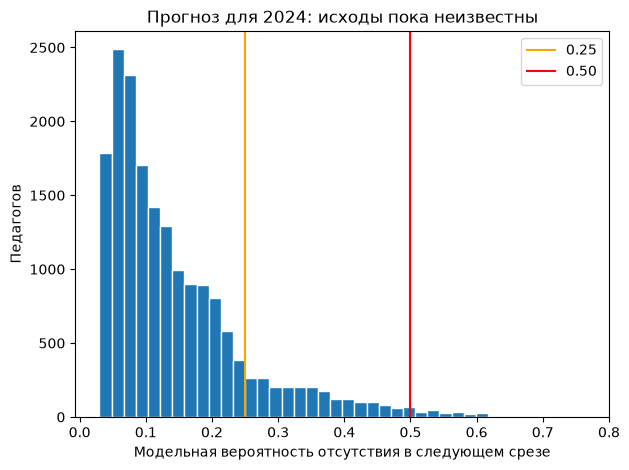

In [11]:
known = df.loc[df["year"].isin([2022, 2023])]
model = deepcopy(best_estimator)
model.fit(known[features], known["target"].astype(int))
forecast_probability = model.predict_proba(X_forecast)[:, 1]
assert np.isfinite(forecast_probability).all()
assert ((forecast_probability >= 0) & (forecast_probability <= 1)).all()

forecast_df = forecast[["id", "year"]].copy()
forecast_df["prob_leave"] = forecast_probability
forecast_df["risk_level"] = np.select(
    [forecast_probability < 0.25, forecast_probability < 0.50],
    ["Низкий", "Средний"], default="Высокий",
)
display(forecast_df["prob_leave"].describe())
display(forecast_df["risk_level"].value_counts())
plt.hist(forecast_probability, bins=40, edgecolor="white")
plt.axvline(0.25, color="orange", label="0.25")
plt.axvline(0.50, color="red", label="0.50")
plt.xlabel("Модельная вероятность отсутствия в следующем срезе")
plt.ylabel("Педагогов")
plt.title("Прогноз для 2024: исходы пока неизвестны")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Короткий вывод для защиты

1. Цель — отсутствие в следующем срезе; переход школы к уходу не относится.
2. Из модели убраны три несопоставимых между годами поля; исходная витрина сохранена.
3. Модели и восемь настроек CatBoost сравнивались по одинаковым OOF-прогнозам 2022.
4. Выбор учитывает AP редкого класса и Brier вероятностей. Большая accuracy не была целью.
5. Параметры и порог зафиксированы до расчёта метрик 2023. Временная проверка отделена от обучения.
6. Для применения на 2024 модель обучена на обоих годах с известными исходами.

Ограничения: всего два года с исходами; 2023 уже изучался в предыдущих опытах;
отсутствие в срезе может быть временным или связано с полнотой выгрузки;
качество вероятностей в 2024 пока не проверить. Прогноз помогает выделять группы внимания,
но не устанавливает причину увольнения и не доказывает эффект изменения признака.

In [12]:
summary = pd.Series({
    "Выбранная модель": best_name,
    "Признаков": len(features),
    "Обучение при оценке": "2022",
    "Проверка": "2023, без настройки на его метках",
    "Обучение для прогноза": "2022 + 2023",
    "AP 2023": round(test_metrics["AP"], 4),
    "ROC-AUC 2023": round(test_metrics["ROC_AUC"], 4),
    "Brier 2023": round(test_metrics["Brier"], 4),
    "Порог по OOF 2022": round(evaluation_threshold, 4),
    "Recall 2023 при этом пороге": round(threshold_results.iloc[0]["recall"], 4),
    "Precision 2023 при этом пороге": round(threshold_results.iloc[0]["precision"], 4),
    "Строк прогноза 2024": len(forecast_df),
})
display(summary.to_frame("Результат"))

,Результат
Выбранная модель,"CatBoost depth=4, trees=300, weights=None"
Признаков,18
Обучение при оценке,2022
Проверка,"2023, без настройки на его метках"
Обучение для прогноза,2022 + 2023
AP 2023,0.2967
ROC-AUC 2023,0.7233
Brier 2023,0.1054
Порог по OOF 2022,0.132
Recall 2023 при этом пороге,0.7199


## 13. Экспорт и проверка сохранения

Сохраняем рабочую модель, отдельную оценочную модель и JSON с признаками, годами,
параметрами и происхождением метрик. Dash читает только `catboost_churn.cbm` и `metadata.json`.
Для проверки сохраняем прогноз и таблицы эксперимента; pickle не используется.
После замены модели приложение нужно перезапустить.

In [13]:
import catboost
import sklearn

MODEL_DIR = root / "models"
MODEL_DIR.mkdir(exist_ok=True)
model.save_model(str(MODEL_DIR / "catboost_churn.cbm"))
evaluation_model.save_model(str(MODEL_DIR / "evaluation_2023.cbm"))

metadata = {
    "schema_version": 1, "task": "binary_leave", "target": "target", "positive_class": 1,
    "features": features, "categorical_features": categorical, "excluded_features": excluded_features,
    "classes": [int(c) for c in model.classes_],
    "training_years": [2022, 2023], "forecast_year": 2024,
    "evaluation_training_years": [2022], "evaluation_year": 2023,
    "evaluation_model_file": "evaluation_2023.cbm",
    "evaluation_used_for_selection": False,
    "evaluation_previously_explored": True,
    "evaluation_note": "Ретроспективная проверка: рецепт выбран внутри 2022; 2023 изучался ранее",
    "selection": "3-fold OOF 2022; highest AP among models beating constant Brier",
    "selected_model": best_name, "model_params": best_params,
    "numeric_missing_policy": "CatBoost native NaN; comparison models use train-fold medians",
    "evaluation_threshold": evaluation_threshold, "threshold_source": "OOF 2022, recall >= 0.70",
    "dashboard_thresholds": [0.25, 0.50],
    "metrics": {"ap": test_metrics["AP"], "roc_auc": test_metrics["ROC_AUC"],
                "brier": test_metrics["Brier"], "logloss": test_metrics["Logloss"]},
    "threshold_metrics": threshold_results.iloc[0].to_dict(),
    "top_groups_2023": top_results.to_dict(orient="records"),
    "versions": {"catboost": catboost.__version__, "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
(MODEL_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
forecast_df.to_parquet(MODEL_DIR / "forecast_2024.parquet", index=False)
cv_results.to_csv(MODEL_DIR / "model_cv_results.csv")
threshold_results.to_csv(MODEL_DIR / "model_thresholds_2023.csv")

loaded = CatBoostClassifier().load_model(str(MODEL_DIR / "catboost_churn.cbm"))
np.testing.assert_allclose(loaded.predict_proba(X_forecast)[:, 1], forecast_probability, rtol=0, atol=1e-12)
assert loaded.feature_names_ == features
assert all(y < metadata["forecast_year"] for y in metadata["training_years"])
print("Сохранение и повторная загрузка проверены:", MODEL_DIR)

Сохранение и повторная загрузка проверены: C:\Users\User\PycharmProjects\hr-teachers\models
